# DINOv2-S/14: attention rollout

Explain all **45 original bandwidth validation images**, including mistakes.
Restore the existing best-validation-accuracy checkpoint: archived result
**43/45**. No training is performed. Classes: **0 Low, 1 High bandwidth**.
Use [START_HERE.md](START_HERE.md) and notebook 00 to set up the computer.
These validation images were used in checkpoint selection; they are not an
independent test set.


In [1]:
from pathlib import Path
import sys
import numpy as np
import torch

# Usually leave this as None. Set a path only if Jupyter starts elsewhere.
PACKAGE_ROOT = None
if PACKAGE_ROOT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p/'package_integrity.json').is_file()
                 and (p/'xai_code').is_dir()), None)
    if ROOT is None:
        raise FileNotFoundError('Start Jupyter inside the extracted package, or set PACKAGE_ROOT.')
else:
    ROOT = Path(PACKAGE_ROOT).expanduser().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from xai_code.models import build_model, Predictor
from xai_code.runtime import prepare, audit_predictions, verify_package, environment, samples
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Package:', ROOT)
print('Device:', DEVICE)


Package: /home/murat/Desktop/original_bandwidth_explainability_lab
Device: cuda


## Configuration

In [2]:
MODEL_NAME = 'dinov2'
METHOD = 'attention_rollout'
BATCH_SIZE = 1  # Reduce this if GPU memory is insufficient.
ALLOW_PREDICTION_DIFFERENCES = False
SETTINGS = {
    'seed': 42,
    'batch_size': BATCH_SIZE,
    'allow_prediction_differences': ALLOW_PREDICTION_DIFFERENCES,
}

SETTINGS.update({'head_fusion': 'mean', 'discard_ratio': 0.0,
                 'residual': 'add identity then row normalize', 'class_specific': False})


## Restore the fixed checkpoint and verify all predictions

In [3]:
OUTPUT = prepare(ROOT, MODEL_NAME, METHOD, SETTINGS, DEVICE)
model = build_model(ROOT, MODEL_NAME, DEVICE)
predictor = Predictor(model, MODEL_NAME, DEVICE, batch_size=BATCH_SIZE)
ROWS, AUDIT = audit_predictions(ROOT, MODEL_NAME, predictor, OUTPUT,
    allow_prediction_differences=ALLOW_PREDICTION_DIFFERENCES)
print('Ready to explain ALL', len(ROWS), 'validation images.')


Integrity OK: 84 fixed files; notebook existence checked separately
Outputs: /home/murat/Desktop/original_bandwidth_explainability_lab/outputs/dinov2/attention_rollout/d78d9c02b3396b76
Validation audit: 43/45; 0 changed predictions
Ready to explain ALL 45 validation images.


## Attention rollout implementation

This is an extension, separate from the original paper's LIME. Average heads,
add residual identity, normalize rows, multiply layers, then read CLS-to-patch
flow. Standard rollout is **not class-specific** and does not explain changes
in a particular output score. Capture probabilities are checked against the
original forward. Per-image maximum normalization makes the display relative.


In [4]:
"""Mean-head attention rollout with residual connections (Abnar & Zuidema)."""
from pathlib import Path
import numpy as np
from PIL import Image
import torch
from xai_code.runtime import read_rgb, write_json, save_figure, summarize


In [5]:
def combine_attention(attentions, grid, prefix_tokens=1):
    """CLS-to-patch flow: normalize(A + I), then multiply in layer order."""
    if not attentions:
        raise ValueError('No attention layers were captured')
    tokens = attentions[0].shape[-1]
    if tokens - prefix_tokens != grid[0]*grid[1]:
        raise ValueError('Attention token count does not match the patch grid')
    identity = torch.eye(tokens, dtype=torch.float64)
    joint = identity.clone()
    layer_means = []
    for attention in attentions:
        if attention.ndim != 4 or attention.shape[0] != 1 or attention.shape[-2:] != (tokens, tokens):
            raise ValueError('Expected one-image attention with shape [1, heads, tokens, tokens]')
        mean = attention[0].detach().to(device='cpu', dtype=torch.float64).mean(dim=0)
        if not torch.isfinite(mean).all() or (mean < 0).any():
            raise ValueError('Invalid attention probabilities')
        augmented = mean + identity
        augmented = augmented/augmented.sum(dim=-1, keepdim=True)
        joint = augmented @ joint
        layer_means.append(mean.numpy())
    raw = joint[0, prefix_tokens:].reshape(grid).numpy()
    relative = raw/raw.max() if raw.max() > 0 else np.zeros_like(raw)
    return raw.astype(np.float32), relative.astype(np.float32), np.stack(layer_means).astype(np.float32)


In [6]:
@torch.inference_mode()
def capture_attention(predictor, rgb):
    model = predictor.model
    name = predictor.model_name
    if name not in ('vit_tiny', 'dinov2'):
        raise ValueError('Ordinary transformer attention rollout is defined here only for ViT-Tiny/DINOv2')
    tensor = predictor.tensor(rgb).unsqueeze(0).to(predictor.device)
    base = model(tensor).softmax(dim=1).cpu().numpy()[0]
    attentions, handles, fused_settings = [], [], []
    try:
        if name == 'vit_tiny':
            def request_weights(module, args, kwargs):
                kwargs = dict(kwargs)
                kwargs['need_weights'] = True
                kwargs['average_attn_weights'] = False
                return args, kwargs
            def capture(module, args, result):
                if result[1] is None:
                    raise RuntimeError('MultiheadAttention did not return attention weights')
                attentions.append(result[1].detach().cpu())
            for block in model.blocks:
                handles.append(block.attention.register_forward_pre_hook(request_weights, with_kwargs=True))
                handles.append(block.attention.register_forward_hook(capture))
            grid, prefix = (14, 14), 1
        else:
            def capture(module, args, result):
                attentions.append(result.detach().cpu())
            for block in model.blocks:
                attention = block.attn
                fused_settings.append((attention, attention.fused_attn))
                # Hook the actual softmax output through attn_drop, preserving
                # timm's q/k normalization and token layout. Dropout is off in eval.
                attention.fused_attn = False
                handles.append(attention.attn_drop.register_forward_hook(capture))
            grid = tuple(model.patch_embed.grid_size)
            prefix = model.num_prefix_tokens
        hooked = model(tensor).softmax(dim=1).cpu().numpy()[0]
    finally:
        for handle in handles:
            handle.remove()
        for module, setting in fused_settings:
            module.fused_attn = setting
    if len(attentions) != len(model.blocks):
        raise RuntimeError('One attention matrix per transformer block was not captured')
    if int(base.argmax()) != int(hooked.argmax()) or not np.allclose(base, hooked, atol=1e-4, rtol=1e-4):
        raise RuntimeError('Attention capture changed inference materially; inspect software/precision before continuing')
    raw, relative, layers = combine_attention(attentions, grid, prefix_tokens=prefix)
    native = np.asarray(Image.fromarray(relative).resize(
        (rgb.shape[1], rgb.shape[0]), resample=Image.Resampling.BILINEAR), dtype=np.float32)
    return raw, relative, native, layers, float(np.max(np.abs(base-hooked)))


In [7]:
def run_rollout(root, rows, audit, predictor, output):
    for index, row in enumerate(rows, start=1):
        destination = output/Path(row['file']).stem
        if all((destination/name).is_file() for name in ['done.json', 'maps.npz', 'explanation.png']):
            print(f"[{index}/45] Already complete: {row['file']}")
            continue
        destination.mkdir(parents=True, exist_ok=True)
        rgb = read_rgb(root, row)
        record = audit[row['file']]
        print(f"[{index}/45] Attention rollout: {row['file']}")
        raw, relative, native, layers, delta = capture_attention(predictor, rgb)
        np.savez_compressed(destination/'maps.npz', raw_patch_flow=raw,
            relative_patch_flow=relative, native_heatmap=native, layer_mean_attention=layers)
        Image.fromarray(rgb).save(destination/'original.png')
        save_figure(rgb, native, 'Attention flow from CLS token', destination/'explanation.png')
        write_json(destination/'done.json', {**record, 'method': 'attention_rollout',
            'class_specific': False, 'head_fusion': 'mean', 'residual': 'add identity then row normalize',
            'patch_rows': raw.shape[0], 'patch_columns': raw.shape[1],
            'attention_capture_probability_difference': delta})
    return summarize(root, rows, audit, output, method='attention_rollout')


## Run rollout for all 45 images; resume completed images

In [8]:
summaries = run_rollout(ROOT, ROWS, AUDIT, predictor, OUTPUT)


[1/45] Attention rollout: M0_log-20241114-212937.bmp
[2/45] Attention rollout: M10_log-20241114-212937.bmp
[3/45] Attention rollout: M11_log-20241114-212937.bmp
[4/45] Attention rollout: M121_log-20241114-212937.bmp
[5/45] Attention rollout: M129_log-20241114-212937.bmp
[6/45] Attention rollout: M136_log-20241114-212937.bmp
[7/45] Attention rollout: M142_log-20241114-212937.bmp
[8/45] Attention rollout: M149_log-20241114-212937.bmp
[9/45] Attention rollout: M154_log-20241114-212937.bmp
[10/45] Attention rollout: M162_log-20241114-212937.bmp
[11/45] Attention rollout: M177_log-20241114-212937.bmp
[12/45] Attention rollout: M178_log-20241114-212937.bmp
[13/45] Attention rollout: M179_log-20241114-212937.bmp
[14/45] Attention rollout: M181_log-20241114-212937.bmp
[15/45] Attention rollout: M187_log-20241114-212937.bmp
[16/45] Attention rollout: M190_log-20241114-212937.bmp
[17/45] Attention rollout: M196_log-20241114-212937.bmp
[18/45] Attention rollout: M1_log-20241114-212937.bmp
[19/45]

## Inspect saved examples, including errors

Saved results: /home/murat/Desktop/original_bandwidth_explainability_lab/outputs/dinov2/attention_rollout/d78d9c02b3396b76
M93_log-20241114-212937.bmp {'file': 'M93_log-20241114-212937.bmp', 'true_label': 0, 'predicted_label': 1, 'probability_low': 0.055394548922777176, 'probability_high': 0.9446054100990295, 'correct': False, 'archived_prediction': 1, 'prediction_changed': False, 'max_probability_difference': 1.1920928955078125e-07}


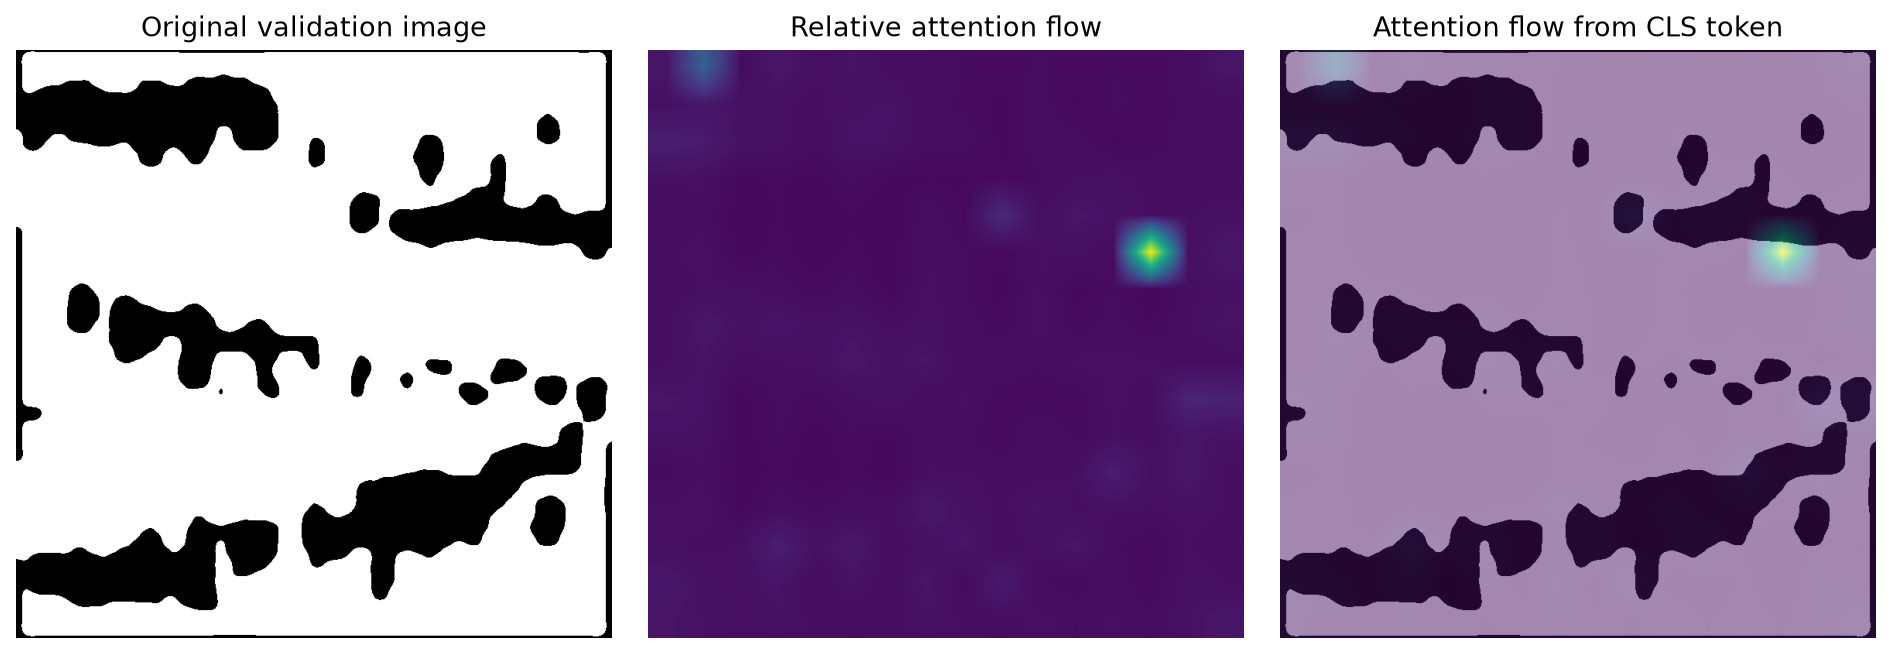

M95_log-20241114-212937.bmp {'file': 'M95_log-20241114-212937.bmp', 'true_label': 0, 'predicted_label': 1, 'probability_low': 0.44132697582244873, 'probability_high': 0.5586730241775513, 'correct': False, 'archived_prediction': 1, 'prediction_changed': False, 'max_probability_difference': 5.900859832763672e-06}


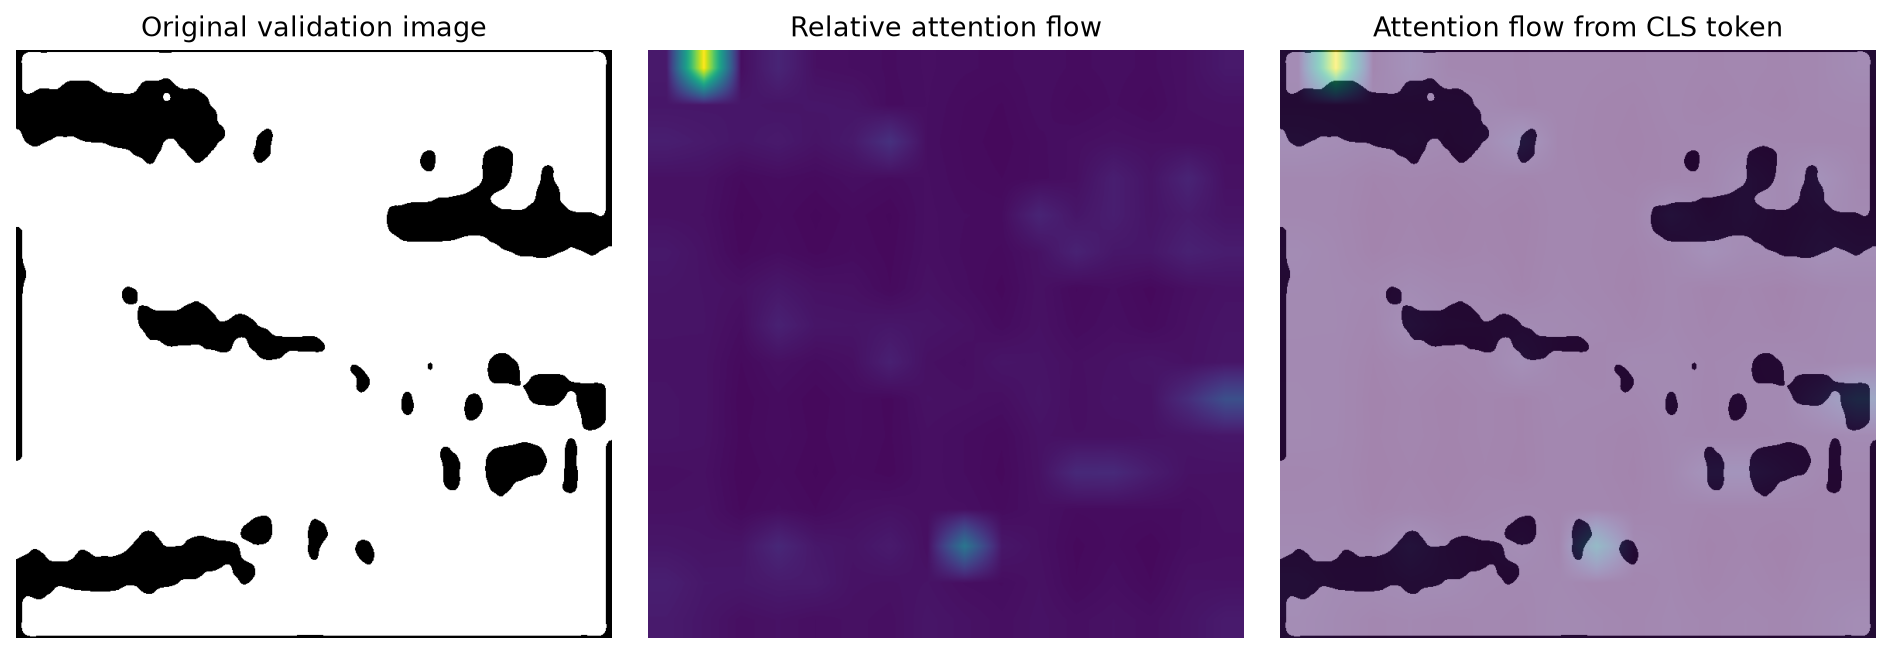

M0_log-20241114-212937.bmp {'file': 'M0_log-20241114-212937.bmp', 'true_label': 0, 'predicted_label': 0, 'probability_low': 0.9683687686920166, 'probability_high': 0.03163114935159683, 'correct': True, 'archived_prediction': 0, 'prediction_changed': False, 'max_probability_difference': 2.123415470123291e-07}


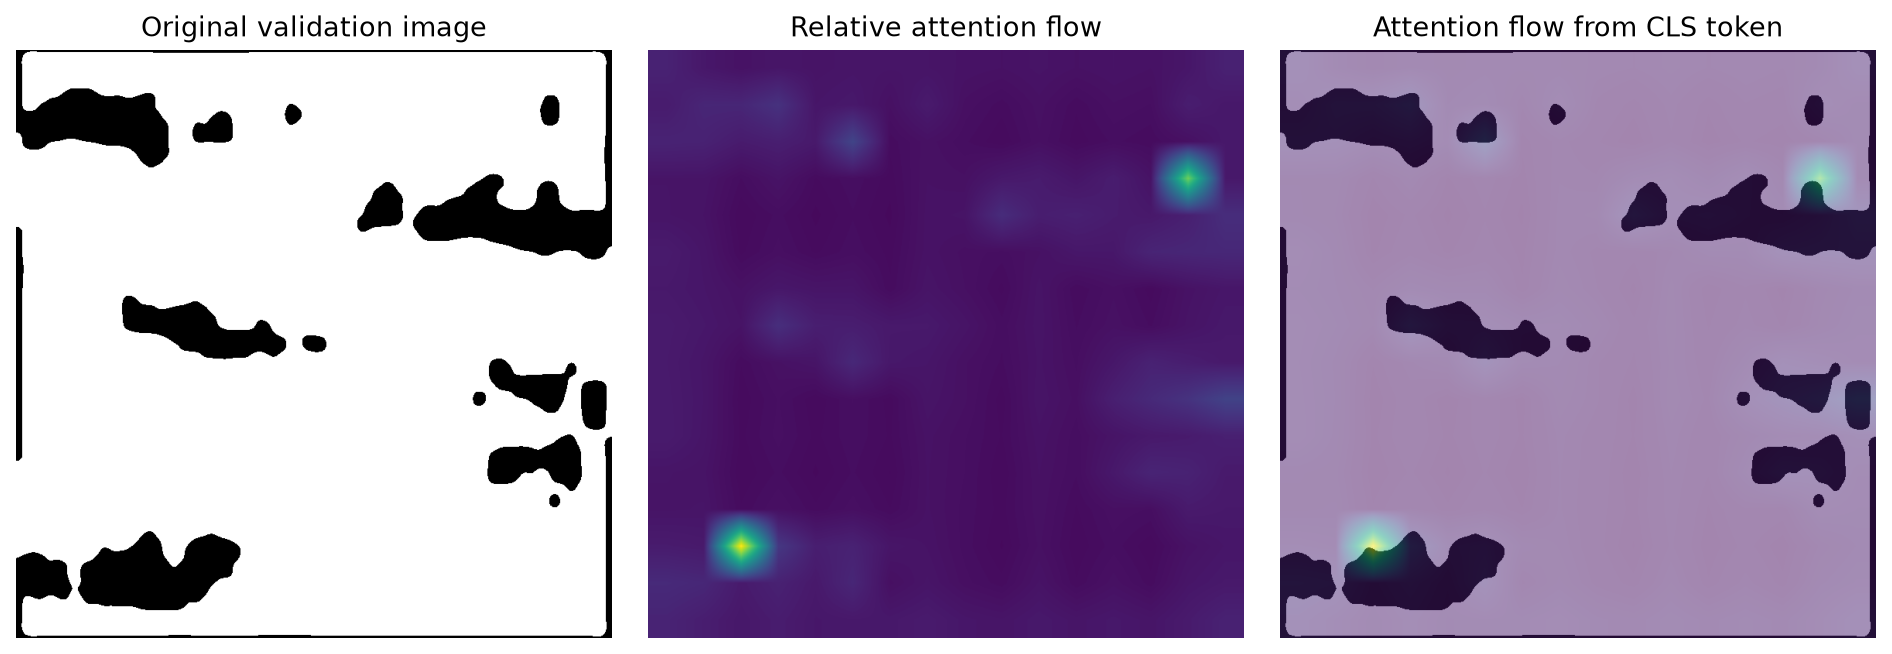

In [9]:
from IPython.display import display, Image as DisplayImage
print('Saved results:', OUTPUT)
error_names = [row['file'] for row in ROWS if not AUDIT[row['file']]['correct']]
example_names = list(dict.fromkeys(error_names + [ROWS[0]['file']]))
for filename in example_names:
    print(filename, AUDIT[filename])
    figure = OUTPUT/Path(filename).stem/'explanation.png'
    if figure.is_file():
        display(DisplayImage(filename=str(figure)))


Outputs include per-image raw maps and metadata, a prediction audit,
summary CSV and class means grouped by predicted class, including mistakes.
Read the local fit scores for LIME. Heatmaps alone do not establish physical
causality. The earlier mean-brightness diagnostic is included in `reference`.

References: [photonic LIME paper](https://advanced.onlinelibrary.wiley.com/doi/10.1002/adpr.202500284),
[LIME](https://github.com/marcotcr/lime),
[attention rollout](https://arxiv.org/abs/2005.00928),
[gradient-weighted rollout variant](https://github.com/jacobgil/vit-explain/blob/main/vit_grad_rollout.py).
